Este código foi criado para desenvolver um modelo de CNN para quantificar células sem estar marcada por fluorescência.

# Imports data structuring

In [1]:
#organização dos arquivos
import os
#salvar/carregar arquivos em diferentes formatos
import joblib
#organizando os arquivos de forma aleatória
import random
#gerar gráfico
import matplotlib
#estruturação dos dados
import numpy as np
#gerar gráfico
import seaborn as sns
#gerar gráfico
import matplotlib.pyplot as plt
#gerar imagem
import matplotlib.image as mpimg

# CNN template import

In [2]:
#modelo de revisão redes neurais - cnn
from keras.models import Sequential
from keras.utils import to_categorical # Import directly from keras.utils
from util import meus_uteis, timeProcess, mask_corr_graphic, printLis
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from keras.layers import Dense, Conv2D, MaxPooling2D, Dropout, Flatten
from sklearn.model_selection import train_test_split

from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ModelCheckpoint

2026-10-16 20:51:22.987687: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-16 20:51:22.991239: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-16 20:51:23.060034: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-16 20:51:23.061150: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/usr/local/lib/python3.10/site-packages/google/api_core/_python_version_support.py:246: FutureWarning: You are us

Documents from different files will be stored in this directory

In [3]:
diretorio = "./data/imagens de contraste de fase (CHO745)/"
lista_dados = [i for i in os.listdir(diretorio) if i.endswith('.gz') and 'lista_' in i] #listando os arquivos dessa pasta
printLis(lista_dados) #printando as diferentes listas

-------------
-=< Lista >=-
-------------
0 -> lista_file_names_resized_regre_cho745_2026-10-16.gz
1 -> lista_img_100_resized_regre_cho745_2026-10-16.gz
2 -> lista_img_25_resized_regre_cho745_2026-10-16.gz
3 -> lista_img_50_resized_regre_cho745_2026-10-16.gz
4 -> lista_img_75_resized_regre_cho745_2026-10-16.gz
5 -> lista_rotulo_100_resized_regre_cho745_2026-10-16.gz
6 -> lista_rotulo_25_resized_regre_cho745_2026-10-16.gz
7 -> lista_rotulo_50_resized_regre_cho745_2026-10-16.gz
8 -> lista_rotulo_75_resized_regre_cho745_2026-10-16.gz


In [4]:
lista_file_names = joblib.load(diretorio+lista_dados[0])
lista_file_names[:3]

array(['test_Experiment_CHO_745_EFGP_v04_ch00_rot648.tif',
       'test_Experiment_CHO_745_EFGP_v11_ch00_rot712.tif',
       'test_Experiment_CHO_745_EFGP_v19_ch00_rot282.tif'], dtype='<U49')

In [5]:
key_test = []
key_train = []
key_valid = []
for k, v in enumerate(lista_file_names):
    if 'test' in v:
        key_test.append(k)
    if 'train' in v:
        key_train.append(k)
    if 'valid' in v:
        key_valid.append(k)

In [6]:
key_test[:3]

[0, 1, 2]

## x = features/images

In [7]:
#1 - 100% somando todas as imagens de diferentes tamanho
X_cem = joblib.load(diretorio+ '/' + lista_dados[1])

# 4 - 75%
X_setcin = joblib.load(diretorio+ '/' + lista_dados[4])

# 3 - 50%
X_cinq = joblib.load(diretorio+ '/' + lista_dados[3])

# 2 - 25%
X_vincin = joblib.load(diretorio+ '/' + lista_dados[2])

x = np.asarray(list(X_cem) + list(X_setcin) + list(X_cinq) + list(X_vincin))

x.shape

(624, 300, 300, 3)

# y = labels

Opening the labels that were saved in the preparation of the images

In [8]:
#1 - 100% somando todos os rótulos de diferentes tamanho
y_cem = joblib.load(diretorio+ '/' + lista_dados[5])

#3 - 75%
y_setcin = joblib.load(diretorio+ '/' + lista_dados[8])

#4 - 50%
y_cinq = joblib.load(diretorio+ '/' + lista_dados[7])

#7 - 25%
y_vincin = joblib.load(diretorio+ '/' + lista_dados[6])

y = np.asarray(list(y_cem) + list(y_setcin) + list(y_cinq) + list(y_vincin))

y.shape

(624,)

In [9]:
#0 - 100% somando todas as imagens de diferentes tamanho
X_cem = joblib.load(diretorio+ '/' + lista_dados[1])

# 2 - 75%
X_setcin = joblib.load(diretorio+ '/' + lista_dados[2])

# 4 - 50%
X_cinq = joblib.load(diretorio+ '/' + lista_dados[3])

# 6 - 25%
X_vincin = joblib.load(diretorio+ '/' + lista_dados[4])

x = np.asarray(list(X_cem) + list(X_setcin) + list(X_cinq) + list(X_vincin))

x.shape

(624, 300, 300, 3)

In [10]:
data = timeProcess()[1]
#Salvando 10$ das imagens para validação
x_valida = x[key_valid]
y_valida = y[key_valid]

Test and training separation from a library.

In [11]:
#salvando os resultados de treino e teste
X_train = x[key_train]
y_train = y[key_train]
X_test = x[key_test]
y_test = y[key_test]

y_train = y_train.astype(int)
y_test = y_test.astype(int)

print(f'''
        {X_train.shape}
        {X_test.shape}
        {x_valida.shape}
        {y_train.shape}
        {y_test.shape}
        {y_valida.shape}
'''
)



        (432, 300, 300, 3)
        (128, 300, 300, 3)
        (64, 300, 300, 3)
        (432,)
        (128,)
        (64,)



### Model determination

In [12]:
modelo = Sequential()
modelo.add(Conv2D(32, kernel_size=3, activation='relu', input_shape=X_train[0].shape))
#função de ativação relu é muito utilizado para problemas de regressão
modelo.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='valid'))
modelo.add(Conv2D(64, kernel_size=3, activation='relu'))
modelo.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='valid'))
modelo.add(Conv2D(128, kernel_size=3, activation='relu'))
modelo.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='valid'))
modelo.add(Conv2D(256, kernel_size=3, activation='relu'))
modelo.add(MaxPooling2D(pool_size=(2, 2), strides=(2, 2), padding='valid'))
modelo.add(Flatten())
modelo.add(Dropout(0.9))
modelo.add(Dense(1, activation='linear'))
#apenas uma saída e de forma linear
modelo.compile(optimizer='adam', loss='mse', metrics=['mean_squared_error'])
print(modelo.summary())

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 298, 298, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 149, 149, 32)     0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 147, 147, 64)      18496     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 73, 73, 64)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 71, 71, 128)       73856     
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 35, 35, 128)      0

# Training and testing epochs

In [13]:
# simple early stopping
es = EarlyStopping(monitor='val_loss', mode='min', verbose=1, patience=18)

In [14]:
# fit model
history = modelo.fit(X_train,y_train,
                    validation_data=(X_test, y_test),
                    epochs=200, verbose=2,
                    callbacks=[es]
                     )

Epoch 1/200
14/14 - 51s - loss: 76405.3984 - mean_squared_error: 76405.3984 - val_loss: 46940.1406 - val_mean_squared_error: 46940.1406 - 51s/epoch - 4s/step
Epoch 2/200
14/14 - 44s - loss: 54166.5742 - mean_squared_error: 54166.5742 - val_loss: 45437.5078 - val_mean_squared_error: 45437.5078 - 44s/epoch - 3s/step
Epoch 3/200
14/14 - 47s - loss: 51359.3242 - mean_squared_error: 51359.3242 - val_loss: 45002.0508 - val_mean_squared_error: 45002.0508 - 47s/epoch - 3s/step
Epoch 4/200
14/14 - 46s - loss: 49139.2930 - mean_squared_error: 49139.2930 - val_loss: 44597.7188 - val_mean_squared_error: 44597.7188 - 46s/epoch - 3s/step
Epoch 5/200
14/14 - 47s - loss: 49092.7461 - mean_squared_error: 49092.7461 - val_loss: 45963.1953 - val_mean_squared_error: 45963.1953 - 47s/epoch - 3s/step
Epoch 6/200
14/14 - 44s - loss: 53784.4727 - mean_squared_error: 53784.4727 - val_loss: 59195.4336 - val_mean_squared_error: 59195.4336 - 44s/epoch - 3s/step
Epoch 7/200
14/14 - 44s - loss: 48930.9727 - mean_sq

## Accuracy Assessment

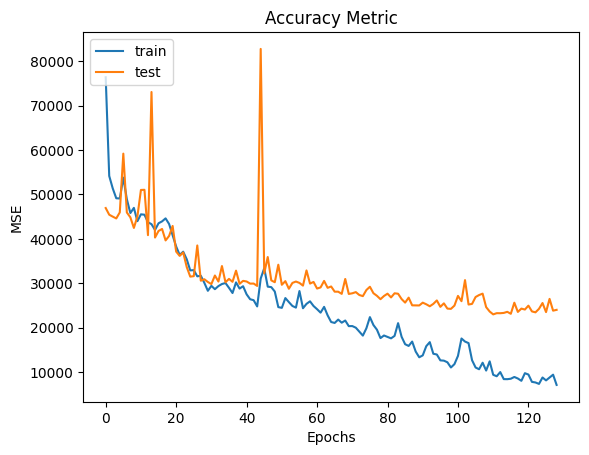

In [15]:
#gráfico avaliando a acurácia a partir de treino e teste
plt.plot(history.history['mean_squared_error'])
plt.plot(history.history['val_mean_squared_error'])
plt.title('Accuracy Metric')
plt.ylabel('MSE')
plt.xlabel('Epochs')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

4/4 [==============================] - 1s 217ms/step


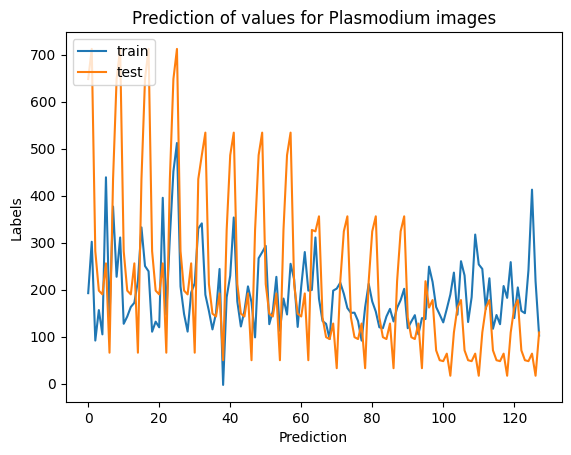

In [22]:
#avaliando a previsão do modelo com os rótulos
prev = modelo.predict(X_test)
plt.title('Prediction of values ​​for Plasmodium images')
plt.ylabel('Labels')
plt.xlabel('Prediction')
plt.plot(prev)#azul - o que o modelo previu
plt.plot(y_test)#laranja - o que se sabe - observado
plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [17]:
# Qualit model analisys
from sklearn.metrics import r2_score,mean_absolute_error, mean_squared_error, mean_squared_log_error, median_absolute_error

In [19]:
#buscando pelas métricas
print(f"{round(r2_score(y_test, prev) * 100, 2)}% r2_score") #raíz quadrada
print(f"{round(mean_absolute_error(y_test, prev), 2)} Erro médio absoluto")
print(f"{round(mean_squared_error(y_test, prev), 2)} Erro médio quadrático") #erro médio quadrático
# print(f"{round(median_absolute_error(y_test, prev), 2)}")#Erro médio absoluto sem %
#print(f"{round(median(y_test, prev), 2)} mediana") #erro médio quavdrático

22.89% r2_score
116.18 Erro médio absoluto
24002.25 Erro médio quadrático


In [20]:
modelo.save( f'{diretorio}modelo_fluore_100_75_50_25_pre_divisao_banco'+data+'.keras')